In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

CONSISTENCY_METRICS_INGEST = Path("../results/benchmark_1_ingest_20261003-114335_runs.csv")
CONSISTENCY_METRICS_TRANS = Path("../results/benchmark_2_transform_20261003-114529_runs.csv")
CONSISTENCY_METRICS_AGG = Path("../results/benchmark_3_aggregate_20261003-114713_runs.csv")

ingest_df = pd.read_csv(CONSISTENCY_METRICS_INGEST)
transform_df = pd.read_csv(CONSISTENCY_METRICS_TRANS)
aggregate_df = pd.read_csv(CONSISTENCY_METRICS_AGG)

9


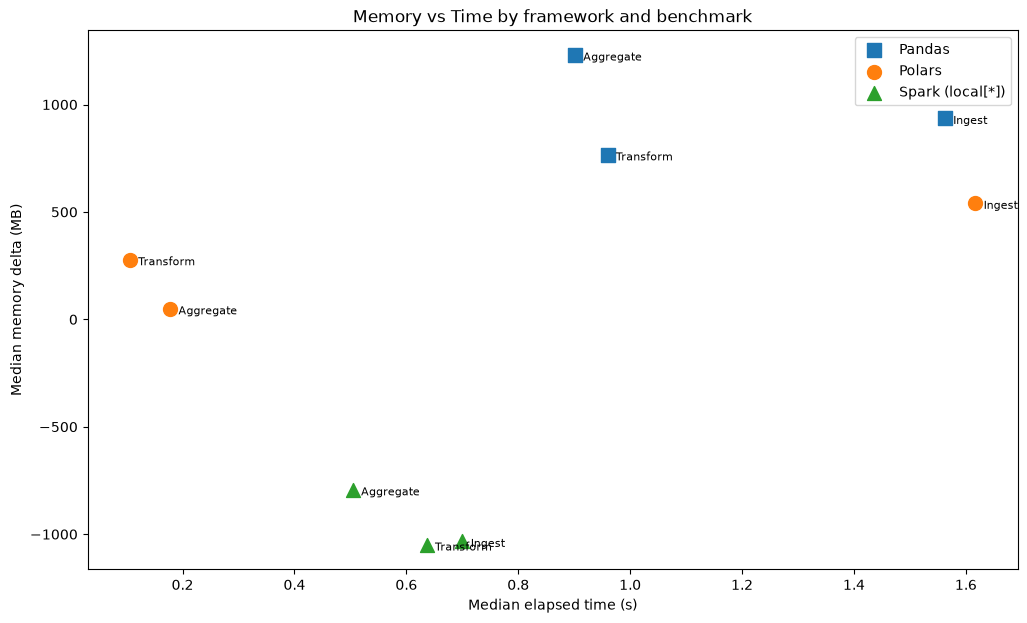

In [28]:
# build a summary row per (framework, benchmark) first
rows = []
for label, df in [("Ingest", ingest_df), ("Transform", transform_df), ("Aggregate", aggregate_df)]:
    timed = df[df["phase"] == "timed"]
    rows.append(timed.groupby("framework")[["elapsed_s", "mem_delta_mb"]].median().assign(benchmark=label))
summary = pd.concat(rows).reset_index()

# then scatter
markers = {"Polars": "o", "Pandas": "s", "Spark (local[*])": "^"}
fig, ax = plt.subplots(figsize=(12, 7))
for fw, grp in summary.groupby("framework"):
    ax.scatter(grp["elapsed_s"], grp["mem_delta_mb"], label=fw, marker=markers[fw], s=100)
    for _, r in grp.iterrows():
        ax.annotate(r["benchmark"], (r["elapsed_s"], r["mem_delta_mb"]),
              textcoords="offset points", xytext=(6, -4), fontsize=8)
ax.set_xlabel("Median elapsed time (s)")
ax.set_ylabel("Median memory delta (MB)")
ax.set_title("Memory vs Time by framework and benchmark")
ax.legend()

print(len(summary))